# APM_50441_EP - Machine Learning 2 - Lab 6: Reinforcement learning

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/APM-50441-EP/APM_50441_EP-2026-2027/blob/main/PC6/APM_50441_EP_Lab_6_simplified_with_solution.ipynb) or run it on your own computer (see *Working environment* below).

This lab illustrates the sixth lecture (*Reinforcement Learning*) on the Cliff Walking problem of the lecture. Its goals are:
- to describe a Markov decision process and its model, and to solve it by dynamic programming (policy evaluation, value iteration, policy iteration),
- to compare Monte Carlo and temporal difference estimation of a value function,
- to implement SARSA and Q-learning, and to understand why they learn different paths,
- to implement the REINFORCE policy gradient in PyTorch, and to see the effect of the reward-to-go on its variance.

The optional *To go further* part, after the core, can be skipped at first: it covers bandits, more temporal difference methods, the deadly triad, deep RL (DQN, actor-critic, PPO) and the RL of language models (GRPO, DPO, agents).

We use `Python` with `numpy`, `gymnasium` and `PyTorch`. The environment, its tabular model and drawing helpers are in the small module `RL.py` (no algorithm in it: you write them).

**Working environment.** Colab is the simplest option: open the notebook of this lab from the course repository (*Open in Colab* link) and run it. To work on your own computer, download the lab folder (the notebook and its files) or clone the course repository, and open the notebook in an IDE that runs Jupyter notebooks (VS Code with the Python and Jupyter extensions, JupyterLab, Spyder, PyCharm). Create a Python environment once with [`uv`](https://docs.astral.sh/uv/): `uv venv`, activate it (`source .venv/bin/activate`, or `.venv\Scripts\activate` on Windows) and `uv pip install jupyter`, or build the whole course environment with `uv sync` in `PC/env`; then select this environment as the kernel of the notebook. The installation cell below installs the packages of the lab into the Python running the notebook (Colab or your environment), and the data are read from the local files when they are present (otherwise they are downloaded).

**Use of AI.** AI assistants are allowed, but you must be able to explain every line you use, and you should answer the *predict before you run* questions before running the code: the suggested code may not be correct!

In [2]:
# Installs into the Python running this notebook: Colab, or locally an activated virtual environment
import sys
!uv pip install --python "{sys.executable}" "gymnasium[toy-text]==1.2.*" "torch" "polars==1.44.2" "seaborn==0.13.2"

Using Python 3.12.14 environment at: ~\.venvs\apm50441
Checked 4 packages in 37ms


In [3]:
import os
import urllib.request
if not os.path.exists("RL.py"):
  urllib.request.urlretrieve("https://raw.githubusercontent.com/APM-50441-EP/APM_50441_EP-2026-2027/main/PC6/RL.py", "RL.py")
import time
import numpy as np
import polars as pl
import seaborn.objects as so
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
torch.set_num_threads(2)
import RL
from RL import NS, NA, START, GOAL, VALID, UP, RIGHT, DOWN, LEFT

## 1. The environment

Cliff Walking (Sutton and Barto, Example 6.6, and the lecture) is a $4 \times 12$ grid: the agent starts in S (bottom left), must reach G (bottom right), and pays $-1$ per step; stepping into the cliff costs $-100$ and sends it back to S. The states are numbered $s = 12 \times \text{row} + \text{column}$ and the actions are $0$ = up, $1$ = right, $2$ = down, $3$ = left. A `gymnasium` environment is used through `reset()` and `step(action)`, which returns the next state, the reward, and whether the episode is *terminated* (goal reached) or *truncated* (time limit).

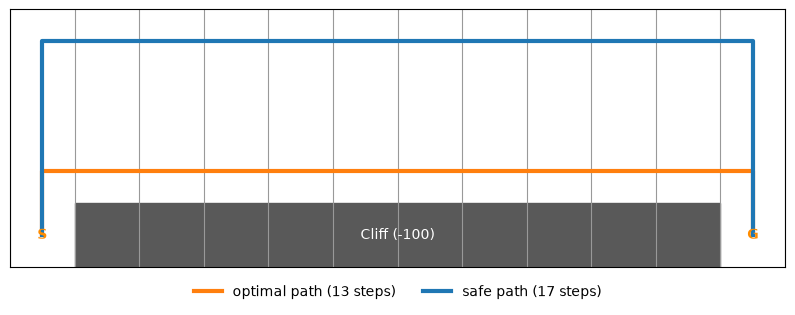

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.5))
RL.draw_grid(ax, paths=[(RL.OPTIMAL_PATH, 'tab:orange', 'optimal path (13 steps)'), (RL.SAFE_PATH, 'tab:blue', 'safe path (17 steps)')])

**Question** *Predict before you run:* what is the average return of the uniformly random policy, with episodes cut after $500$ steps? Run $200$ such episodes in `RL.make_env(max_steps=500)` and report the mean return, the mean length and the proportion of episodes reaching the goal.

**Answer**

In [5]:
env = RL.make_env(max_steps=500)
env.action_space.seed(0)
episodes = []
for episode in range(200):
  s, _ = env.reset(seed=episode)
  total, length, done = 0, 0, False
  while not done:
    s, r, terminated, truncated, _ = env.step(env.action_space.sample())
    total, length, done = total + r, length + 1, terminated or truncated
  episodes.append({'return': total, 'length': length, 'goal': terminated})
pl.DataFrame(episodes).mean()

return,length,goal
f64,f64,f64
-5054.355,486.495,0.07


**Conclusion** The uniformly random policy is terrible: the mean return over $500$ steps is about $-5000$, as the agent falls into the cliff about $45$ times per episode ($-100$ each) on top of the $-1$ per step, and only $7\%$ of the episodes reach the goal within $500$ steps. Exploring at random in this environment is very costly, which is why the exploration of the learning algorithms below matters.

---

The lecture also uses a *slippery* version: with probability $10\%$, the chosen action is replaced by a uniformly random one. `RL.tabular_model(slip)` returns its model: the transition probabilities `P[s, a, s']` and the expected rewards `R[s, a]` (the goal is absorbing, with reward $0$).

**Question** Build the model with `slip=0.1`. Check that each `P[s, a]` is a probability distribution. Where can the agent go from S when it chooses *right*, with which probabilities? Compute `R[START, RIGHT]` by hand and compare.

**Answer**

In [6]:
P, R = RL.tabular_model(slip=0.1)
print('rows sum to one:', np.allclose(P.sum(axis=2), 1))
print({int(s2): round(float(p), 3) for s2, p in enumerate(P[START, RIGHT]) if p > 0})
{'R[START, RIGHT]': R[START, RIGHT], 'by hand': 0.9 * (-100) + 0.1 * (-1 - 100 - 1 - 1) / 4}

rows sum to one: True
{24: 0.025, 36: 0.975}


{'R[START, RIGHT]': np.float64(-92.57500000000002), 'by hand': -92.575}

**Conclusion** Every `P[s, a]` sums to $1$. From S, choosing *right* sends the agent to S again with probability $0.975$ (the cliff sends it back to S, and the slips *down* and *left* bump into the wall), and *up* with probability $0.025$ (a slip). The expected reward is $0.9 \times (-100) + 0.1 \times \frac{-1 - 100 - 1 - 1}{4} = -92.575$, as computed by the model: with probability $0.9 + 0.025$, the agent falls.

---

## 2. Dynamic programming

With a known model and a discount $\gamma = 0.9$, the value of a stationary policy $\pi$ solves the Bellman equation $v_\pi = r_\pi + \gamma P_\pi v_\pi$, with $P_\pi(s, s') = \sum_a \pi(a|s)P(s, a, s')$ and $r_\pi(s) = \sum_a\pi(a|s)R(s, a)$. It can be computed exactly by solving this linear system, or by iterating the Bellman operator $v \mapsto r_\pi + \gamma P_\pi v$, a $\gamma$-contraction for the sup norm (PC6). The optimal value $v_\star$ is the fixed point of the *optimal* Bellman operator $v \mapsto \max_a\big(R(\cdot, a) + \gamma P(\cdot, a)v\big)$.

**Question** For the uniform policy on the slippery grid ($\gamma = 0.9$), compute $v_\pi$ exactly with `np.linalg.solve`, then by $60$ iterations of the Bellman operator from $v = 0$. Plot the sup-norm error (over the valid states) along the iterations in log scale, with the bound $\gamma^k\|v_0 - v_\pi\|_\infty$. Display $v_\pi$ on the grid.

**Answer**

v_uniform(S) = -150.8961022437207


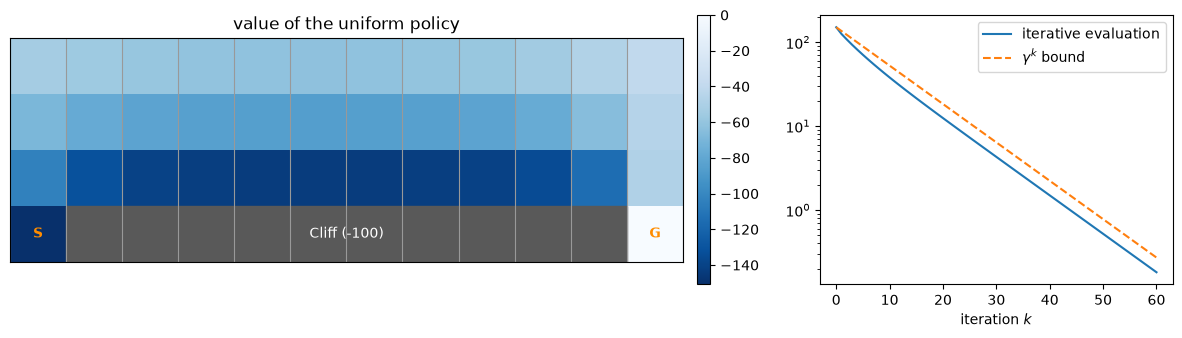

In [7]:
gamma = 0.9
uniform = np.full((NS, NA), 1 / NA)
def evaluate(pi, P=P, R=R, gamma=gamma):
  P_pi, r_pi = np.einsum('sa,sat->st', pi, P), (pi * R).sum(axis=1)
  return np.linalg.solve(np.eye(NS) - gamma * P_pi, r_pi)
v_uniform = evaluate(uniform)
P_pi, r_pi = np.einsum('sa,sat->st', uniform, P), (uniform * R).sum(axis=1)
v, errors = np.zeros(NS), []
for k in range(61):
  errors.append(np.abs(v - v_uniform)[VALID].max())
  v = r_pi + gamma * P_pi @ v
fig, axes = plt.subplots(1, 2, figsize=(15, 3.5), gridspec_kw=dict(width_ratios=[2, 1]))
RL.draw_grid(axes[0], values=v_uniform, title='value of the uniform policy')
axes[1].semilogy(errors, label='iterative evaluation')
axes[1].semilogy(errors[0] * gamma ** np.arange(61), '--', label=r'$\gamma^k$ bound')
axes[1].legend(); axes[1].set_xlabel('iteration $k$')
print('v_uniform(S) =', v_uniform[START])

**Conclusion** The value of the uniform policy from S is $-151$ (with $\gamma = 0.9$): the states next to the cliff have the lowest values, since a random move falls with probability $1/4$. The iterative evaluation converges geometrically, and its error stays below the bound $\gamma^k\|v_0 - v_\pi\|_\infty$: the Bellman operator is a $\gamma$-contraction for the sup norm (PC6), so that the number of iterations needed for a precision $\varepsilon$ is about $\log(\varepsilon)/\log(\gamma)$. The exact solution of the linear system gives the same result directly, at a cost cubic in the number of states.

---

**Question** Implement value iteration (iterate the optimal Bellman operator from $v = 0$ until the sup-norm change is below $10^{-10}$). Display $v_\star$ with the greedy policy $\arg\max_a\big(R(s, a) + \gamma P(s, a)v_\star\big)$ and its path from S (without slips). Then solve the problem without slips (`slip=0`) and compare the paths.

**Answer**

{'iterations': 63,
 'v*(S), slip 10%': np.float64(-11.353475009722432),
 'v*(S), no slip': np.float64(-7.458134171671),
 'path length, slip 10%': 15,
 'path length, no slip': 13}

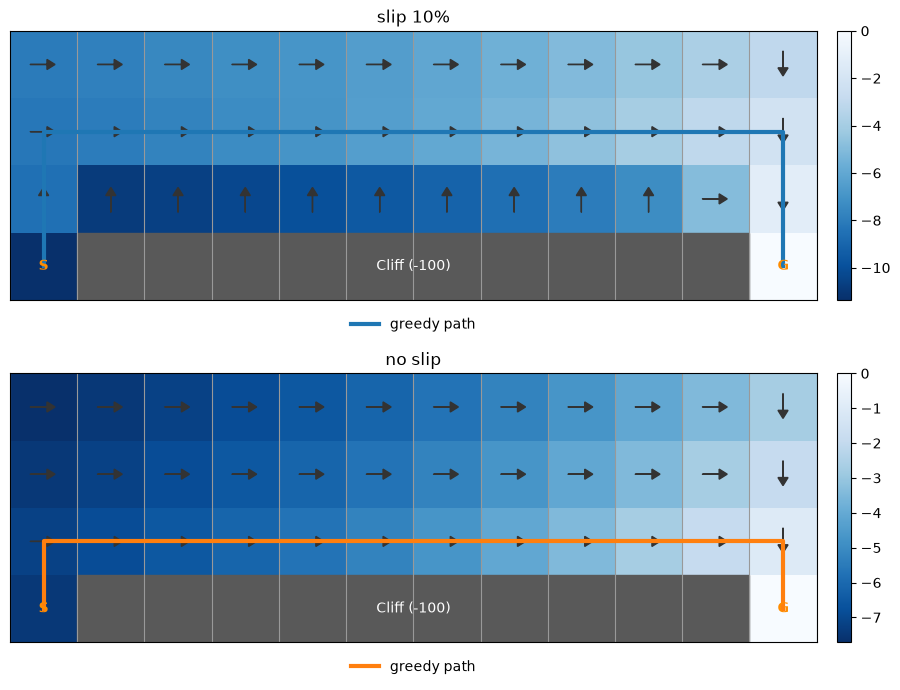

In [8]:
def value_iteration(P, R, gamma=0.9, tol=1e-10):
  v = np.zeros(NS)
  for iteration in range(10_000):
    v_new = (R + gamma * P @ v).max(axis=1)
    if np.abs(v_new - v).max() < tol:
      return v_new, iteration + 1
    v = v_new
v_star, iterations = value_iteration(P, R)
greedy = (R + gamma * P @ v_star).argmax(axis=1)
P0, R0 = RL.tabular_model(slip=0.0)
v_star0, _ = value_iteration(P0, R0)
greedy0 = (R0 + gamma * P0 @ v_star0).argmax(axis=1)
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
RL.draw_grid(axes[0], values=v_star, actions=greedy, paths=[(RL.greedy_path(greedy), 'tab:blue', 'greedy path')], title='slip 10%')
RL.draw_grid(axes[1], values=v_star0, actions=greedy0, paths=[(RL.greedy_path(greedy0), 'tab:orange', 'greedy path')], title='no slip')
fig.tight_layout()
{'iterations': iterations, 'v*(S), slip 10%': v_star[START], 'v*(S), no slip': v_star0[START],
 'path length, slip 10%': len(RL.greedy_path(greedy)) - 1, 'path length, no slip': len(RL.greedy_path(greedy0)) - 1}

**Conclusion** Value iteration converges in $63$ iterations. With $10\%$ of slips, $v_\star(S) = -11.35$ and the greedy path climbs two rows away from the cliff before going right ($15$ steps): one step along the cliff risks a fall with probability $2.5\%$, at a cost of $-100$, which is not worth the $2$ steps saved. Without slips, the optimal path goes right along the cliff ($13$ steps, $v_\star(S) = -7.46$ with discount). The arrows of the greedy policy point away from the cliff everywhere near it: the optimal policy depends on the risk, not only on the shortest path.

---

**Question** Implement policy iteration: start from the policy "always right" (which walks into the cliff), evaluate it exactly, take the greedy policy, and repeat until the policy does not change. How many iterations are needed? Plot the sup-norm error $\|v_{\pi_k} - v_\star\|_\infty$ along the iterations together with the one of value iteration.

**Answer**

{'policy iteration steps': 13, 'same policy as value iteration': True}

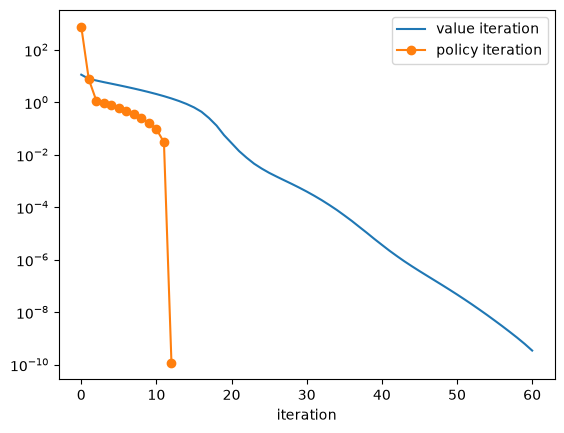

In [9]:
actions, pi_errors = np.full(NS, RIGHT), []
while True:
  v_pi = evaluate(np.eye(NA)[actions])
  pi_errors.append(np.abs(v_pi - v_star)[VALID].max())
  new_actions = (R + gamma * P @ v_pi).argmax(axis=1)
  if np.array_equal(new_actions, actions):
    break
  actions = new_actions
v, vi_errors = np.zeros(NS), []
for k in range(61):
  vi_errors.append(np.abs(v - v_star)[VALID].max())
  v = (R + gamma * P @ v).max(axis=1)
plt.semilogy(vi_errors, label='value iteration')
plt.semilogy(np.maximum(pi_errors, 1e-14), 'o-', label='policy iteration')
plt.xlabel('iteration'); plt.legend()
{'policy iteration steps': len(pi_errors), 'same policy as value iteration': bool(np.array_equal(actions[VALID], greedy[VALID]))}

**Conclusion** Policy iteration converges in $13$ iterations to the same policy as value iteration. Its error decreases much faster than the geometric rate of value iteration, and becomes exactly $0$ (up to the precision of the linear solver) when the policy stops changing: each iteration is more expensive (an exact policy evaluation) but improves the policy a lot, and there are only finitely many deterministic policies.

---

## 3. Monte Carlo and temporal difference estimation

Without a model, the value of a policy is estimated from episodes. *Monte Carlo* (MC) moves $V(s_t)$ towards the observed return $G_t$; *temporal difference* TD(0) moves it towards the *bootstrapped* target $r_{t+1} + \gamma V(s_{t+1})$, after each step. We compare them on the random walk of the lecture (Sutton and Barto, Example 6.2): $5$ states A to E, start in C, left or right with probability $1/2$, reward $1$ when leaving on the right; the true values are $1/6, \dots, 5/6$. `RL.random_walk_episode(rng)` returns the transitions $(s, r, s')$ of an episode ($s' = $ `None` at the end).

**Question** Implement every-visit MC and TD(0) with a constant step size $\alpha$ and the values initialized at $0.5$ (no discount). For $\alpha \in \{0.01, 0.02, 0.05, 0.1, 0.2, 0.3\}$, compute the RMS error over the $5$ states after each of $100$ episodes, averaged over $100$ runs. Plot the curves of the best $\alpha$ of each method, and the final error (mean over the last $10$ episodes) as a function of $\alpha$.

**Answer**

alpha,MC,TD
f64,f64,f64
0.01,0.098186,0.131978
0.02,0.080903,0.073683
0.05,0.118159,0.036579
0.1,0.167994,0.05511
0.2,0.222961,0.08237
0.3,0.27432,0.11061


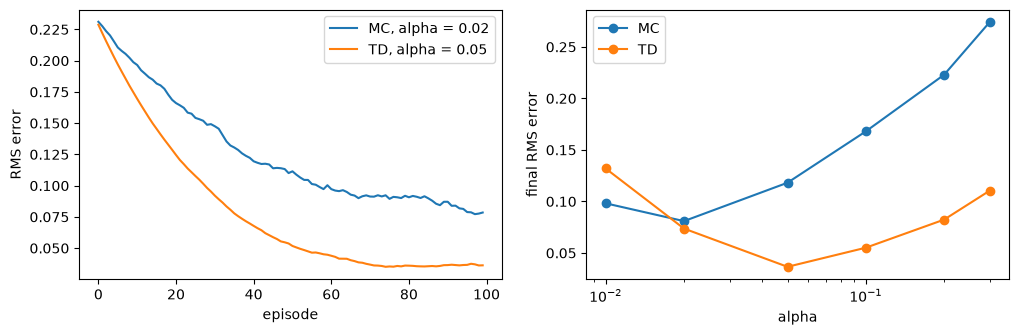

In [10]:
V_true = np.arange(1, 6) / 6
def estimate(method, alpha, n_episodes, rng, step_size=None):
  V, counts, errors = np.full(5, 0.5), np.zeros(5), np.zeros(n_episodes)
  for e in range(n_episodes):
    transitions = RL.random_walk_episode(rng)
    if method == 'TD':
      for s, r, s2 in transitions:
        counts[s] += 1
        a = alpha if step_size is None else step_size(counts[s])
        V[s] += a * (r + (V[s2] if s2 is not None else 0.0) - V[s])
    else:
      G = 0.0
      for s, r, s2 in reversed(transitions):
        G += r
        counts[s] += 1
        a = alpha if step_size is None else step_size(counts[s])
        V[s] += a * (G - V[s])
    errors[e] = np.sqrt(np.mean((V - V_true) ** 2))
  return errors
rng = np.random.default_rng(0)
alphas = [0.01, 0.02, 0.05, 0.1, 0.2, 0.3]
curves = {(m, a): np.mean([estimate(m, a, 100, rng) for _ in range(100)], axis=0) for m in ['MC', 'TD'] for a in alphas}
final = pl.DataFrame([{'method': m, 'alpha': a, 'final RMS': curves[m, a][-10:].mean()} for m, a in curves])
best = {m: final.filter(pl.col('method') == m).sort('final RMS')['alpha'][0] for m in ['MC', 'TD']}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for m in ['MC', 'TD']:
  axes[0].plot(curves[m, best[m]], label=f'{m}, alpha = {best[m]}')
  axes[1].plot(alphas, [curves[m, a][-10:].mean() for a in alphas], 'o-', label=m)
axes[0].set_xlabel('episode'); axes[0].set_ylabel('RMS error'); axes[0].legend()
axes[1].set_xscale('log'); axes[1].set_xlabel('alpha'); axes[1].set_ylabel('final RMS error'); axes[1].legend()
final.pivot(on='method', index='alpha', values='final RMS')

**Conclusion** TD(0) reaches lower errors than MC: its best final RMS error is $0.037$ (for $\alpha = 0.05$) against $0.081$ for MC (for $\alpha = 0.02$), and it is better for every step size above $0.01$. TD uses the current estimates of the neighboring states (bootstrapping), which reduces the variance of its targets; MC uses the full returns, unbiased but noisier. With larger step sizes, both errors increase: the estimates keep fluctuating around the true values (the lecture's $0.08$ / $0.04$).

---

**Question** With a constant step size, the estimates keep fluctuating. Compare, over $1000$ episodes ($20$ runs), MC and TD(0) with $\alpha = 0.05$ and with the decreasing step size $\alpha_n = 1/n$ ($n$ = number of updates of the state). Which ones converge to the true values? (PC6, Exercise 2.)

**Answer**

{'MC, alpha = 0.05': 0.1181,
 'MC, alpha = 1/n': 0.018,
 'TD, alpha = 0.05': 0.0342,
 'TD, alpha = 1/n': 0.0277}

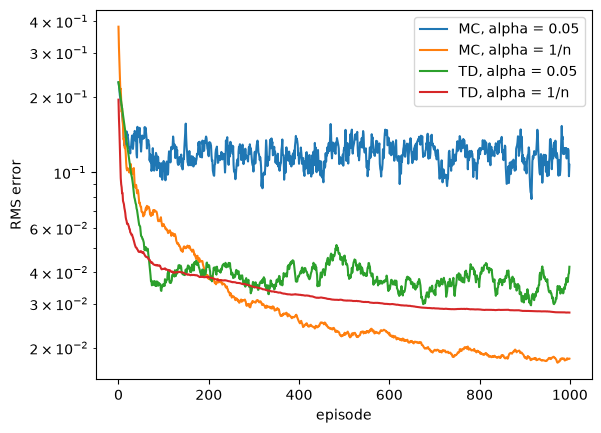

In [11]:
rng = np.random.default_rng(1)
long = {(m, name): np.mean([estimate(m, 0.05, 1000, rng, step) for _ in range(20)], axis=0)
        for m in ['MC', 'TD'] for name, step in [('alpha = 0.05', None), ('alpha = 1/n', lambda n: 1 / n)]}
for (m, name), c in long.items():
  plt.plot(c, label=f'{m}, {name}')
plt.yscale('log'); plt.xlabel('episode'); plt.ylabel('RMS error'); plt.legend()
{f'{m}, {name}': round(float(c[-50:].mean()), 4) for (m, name), c in long.items()}

**Conclusion** With a constant step size $\alpha = 0.05$, the errors stop decreasing (MC $0.118$, TD $0.034$ after $1000$ episodes): the estimates keep moving with the last episodes. With $\alpha_n = 1/n$, they keep decreasing ($0.018$ for MC, $0.028$ for TD): for MC, $1/n$ gives the empirical mean of the returns, which converges to the true value (law of large numbers); TD also converges under the Robbins–Monro conditions $\sum\alpha_n = \infty$, $\sum\alpha_n^2 < \infty$ (PC6). A constant step size is preferred when the problem is non-stationary (e.g. in control, where the policy changes).

---

## 4. SARSA and Q-learning

Without a model, control learns the action values $Q(s, a)$ from the transitions, while acting $\varepsilon$-greedily. After a transition $(s, a, r, s')$ and the choice of the next action $a'$:
- SARSA (on-policy) uses the target $r + \gamma Q(s', a')$: it learns the value of the $\varepsilon$-greedy policy it follows,
- Q-learning (off-policy) uses the target $r + \gamma\max_b Q(s', b)$: it learns the value of the greedy policy.

As in the lecture, we use $\varepsilon = 0.1$, $\alpha = 0.5$, no discount, and no slip.

**Question** *Predict before you run:* which method will collect more reward during learning? Implement both on `RL.make_env(max_steps=1000)` ($500$ episodes, ties broken at random, $Q$ initialized at $0$), average the reward per episode over $20$ runs, and plot it (smoothed over $10$ episodes). Draw the greedy paths of the learned $Q$ (averaged over the runs).

**Answer**

SARSA: mean reward per episode over the last 100 episodes -26.6, greedy path 17 steps
Q-learning: mean reward per episode over the last 100 episodes -50.5, greedy path 13 steps


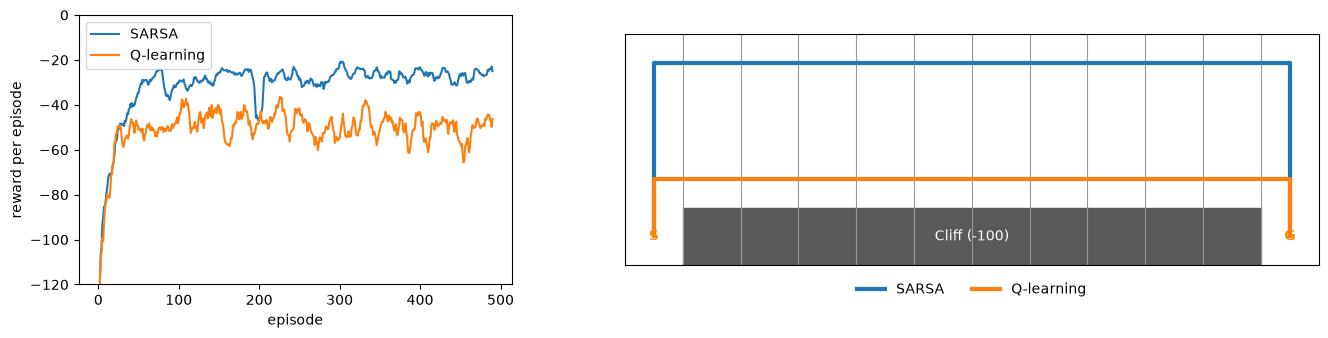

In [12]:
def epsilon_greedy(q, epsilon, rng):
  if rng.random() < epsilon:
    return int(rng.integers(NA))
  return int(rng.choice(np.flatnonzero(q == q.max())))

def td_control(method, n_episodes=500, alpha=0.5, epsilon=0.1, seed=0):
  rng, env = np.random.default_rng(seed), RL.make_env(max_steps=1000)
  Q, returns = np.zeros((NS, NA)), np.zeros(n_episodes)
  for e in range(n_episodes):
    s, _ = env.reset(seed=seed * 10_000 + e)
    a, done = epsilon_greedy(Q[s], epsilon, rng), False
    while not done:
      s2, r, terminated, truncated, _ = env.step(a)
      a2 = epsilon_greedy(Q[s2], epsilon, rng)
      target = r if terminated else r + (Q[s2, a2] if method == 'SARSA' else Q[s2].max())
      Q[s, a] += alpha * (target - Q[s, a])
      s, a, returns[e], done = s2, a2, returns[e] + r, terminated or truncated
  return Q, returns

results = {m: [td_control(m, seed=run) for run in range(20)] for m in ['SARSA', 'Q-learning']}
fig, axes = plt.subplots(1, 2, figsize=(16, 3.5), gridspec_kw=dict(width_ratios=[1, 1.6]))
paths = []
for m, color in [('SARSA', 'tab:blue'), ('Q-learning', 'tab:orange')]:
  curve = np.mean([r for _, r in results[m]], axis=0)
  axes[0].plot(np.convolve(curve, np.ones(10) / 10, mode='valid'), color=color, label=m)
  paths.append((RL.greedy_path(np.mean([q for q, _ in results[m]], axis=0).argmax(axis=1)), color, m))
  print(f'{m}: mean reward per episode over the last 100 episodes {curve[-100:].mean():.1f}, greedy path {len(paths[-1][0]) - 1} steps')
axes[0].set_ylim(-120, 0); axes[0].set_xlabel('episode'); axes[0].set_ylabel('reward per episode'); axes[0].legend()
RL.draw_grid(axes[1], paths=paths)

**Conclusion** SARSA collects more reward during learning (about $-27$ per episode against $-50$ for Q-learning), although Q-learning learns the optimal path along the cliff ($13$ steps) and SARSA the safe path along the top ($17$ steps). Q-learning learns the value of the greedy policy, but it acts $\varepsilon$-greedily: along the cliff, the random moves often make it fall. SARSA learns the value of the policy it actually follows, exploration included, and therefore avoids the cliff. The difference disappears if $\varepsilon$ goes to $0$.

---

## 5. Policy gradient: REINFORCE in PyTorch

A policy gradient method optimizes a parametrized policy directly. With a tabular softmax policy $\pi_\theta(a|s) \propto e^{\theta_{s,a}}$, the REINFORCE estimator of $\nabla_\theta J(\theta)$ for an episode $(s_0, a_0, r_1, \dots)$ is $\sum_t G\,\nabla_\theta\log\pi_\theta(a_t|s_t)$, with either the total return $G = G_0$ or, using causality, the *reward-to-go* $G = G_t = \sum_{t' \geq t} r_{t'+1}$ (PC6). In PyTorch, gradient descent uses the negative of this estimate, the gradient of the loss $-\sum_t G\log\pi_\theta(a_t|s_t)$, computed by automatic differentiation.

To keep the episodes short, they start from a random valid state and are cut after $100$ steps (no discount, no slip). The quality of a policy is measured exactly with the model: `expected_return` computes the expected sum of rewards over $100$ steps from S and averaged over the training start distribution (backward induction).

Training optimizes the average over random valid starting states. The return from S is a separate evaluation metric.

In [13]:
P0, R0 = RL.tabular_model(slip=0.0)
STARTS = [s for s in range(NS) if VALID[s] and s != GOAL]
def expected_return(theta, horizon=100):
  pi = torch.softmax(theta, dim=1).detach().numpy()
  P_pi, r_pi = np.einsum('sa,sat->st', pi, P0), (pi * R0).sum(axis=1)
  v = np.zeros(NS)
  for _ in range(horizon):
    v = r_pi + P_pi @ v
  return v[START], v[STARTS].mean()

**Question** Write a function sampling an episode with the policy $\text{softmax}(\theta)$ (return the states, the actions, the rewards, the final successor and the termination flags), and the REINFORCE loss with the full return or the reward-to-go. Train $\theta$ (initialized at $0$, plain SGD with step sizes $3\cdot10^{-4}$ for the full return and $10^{-3}$ for the reward-to-go) for $4000$ episodes, $3$ runs each, and plot the return from S every $100$ episodes. Report the final median from S and from a uniformly random valid nonterminal state. The optimum from S is $-13$.

**Answer**

197 s
shape: (2, 3)
┌──────────────┬─────────────────┬─────────────────────┐
│ estimator    ┆ expected return ┆ random-start return │
│ ---          ┆ ---             ┆ ---                 │
│ str          ┆ f64             ┆ f64                 │
╞══════════════╪═════════════════╪═════════════════════╡
│ reward-to-go ┆ -23.572791      ┆ -12.786485          │
│ full return  ┆ -99.575824      ┆ -37.905843          │
└──────────────┴─────────────────┴─────────────────────┘


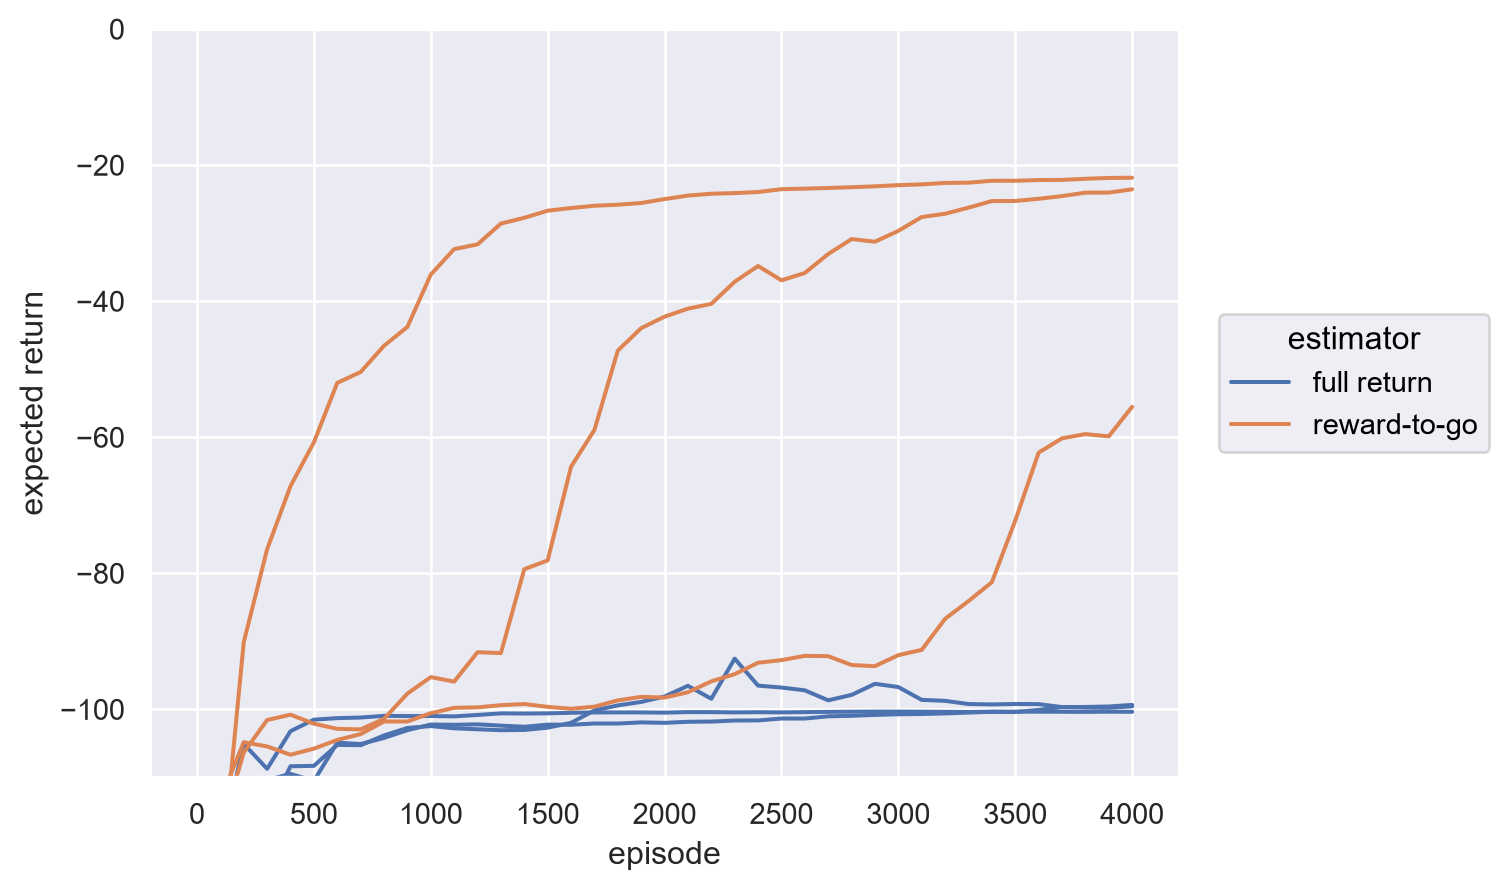

In [14]:
env = RL.make_env(max_steps=100)
def sample_episode(theta, rng):
  s = RL.reset_to(env, STARTS[rng.integers(len(STARTS))])
  states, actions, rewards, done = [], [], [], False
  probabilities = torch.softmax(theta, dim=1).detach().numpy()
  while not done:
    a = rng.choice(NA, p=probabilities[s])
    s2, r, terminated, truncated, _ = env.step(a)
    states.append(s); actions.append(a); rewards.append(r)
    s, done = s2, terminated or truncated
  return torch.tensor(states), torch.tensor(actions), torch.tensor(rewards, dtype=torch.float32), s, terminated, truncated

def reinforce_loss(theta, states, actions, rewards, reward_to_go):
  log_pi = torch.log_softmax(theta[states], dim=1)[torch.arange(len(actions)), actions]
  G = torch.flip(torch.cumsum(torch.flip(rewards, [0]), 0), [0]) if reward_to_go else rewards.sum().expand(len(rewards))
  return -(G * log_pi).sum()

def train_reinforce(reward_to_go, lr, n_episodes=4000, seed=0):
  rng = np.random.default_rng(seed)
  theta = torch.zeros(NS, NA, requires_grad=True)
  optimizer = torch.optim.SGD([theta], lr=lr)
  curve = []
  for e in range(n_episodes + 1):
    if e % 100 == 0:
      from_start, random_start = expected_return(theta)
      curve.append({'episode': e, 'expected return': from_start, 'random-start return': random_start})
    loss = reinforce_loss(theta, *sample_episode(theta, rng)[:3], reward_to_go)
    optimizer.zero_grad(); loss.backward(); optimizer.step()
  return curve

start = time.perf_counter()
curves = pl.concat([pl.DataFrame(train_reinforce(rtg, lr, seed=run)).with_columns(estimator=pl.lit(name), run=pl.lit(run))
                    for name, rtg, lr in [('full return', False, 3e-4), ('reward-to-go', True, 1e-3)] for run in range(3)])
print(f'{time.perf_counter() - start:.0f} s')
print(curves.filter(pl.col('episode') == 4000).group_by('estimator').agg(pl.col('expected return', 'random-start return').median()))
so.Plot(curves, x='episode', y='expected return', color='estimator', group='run').add(so.Line()).limit(y=(-110, 0))

**Conclusion** After 4000 episodes, median return from S is $-23.6$ with reward-to-go and $-99.6$ with the full return. Averaging over the random starts used for training gives $-12.8$ and $-37.9$, respectively. The learning rates differ. The next experiment measures gradient variance directly at a fixed policy.

---

**Question** At the initial policy ($\theta = 0$), sample $2000$ episodes and compute, for each of them, the coordinate $\partial/\partial\theta_{S,\text{up}}$ of the gradient of the REINFORCE objective (minus the gradient of the loss) with both estimators. Compare their means and standard deviations. Why is the reward-to-go legitimate, and why does it help?

**Answer**

In [15]:
rng = np.random.default_rng(0)
theta0 = torch.zeros(NS, NA, requires_grad=True)
coordinates = {'full return': [], 'reward-to-go': []}
for _ in range(2000):
  episode = sample_episode(theta0, rng)
  for name, rtg in [('full return', False), ('reward-to-go', True)]:
    (gradient,) = torch.autograd.grad(-reinforce_loss(theta0, *episode[:3], rtg), theta0)
    coordinates[name].append(gradient[START, UP].item())
{name: {'mean': np.mean(g), 'standard deviation': np.std(g)} for name, g in coordinates.items()}

{'full return': {'mean': np.float64(400.678625),
  'standard deviation': np.float64(2735.7472538479974)},
 'reward-to-go': {'mean': np.float64(396.67425),
  'standard deviation': np.float64(1560.0098328454337)}}

**Conclusion** Both estimators have the same mean (about $400$, up to the Monte Carlo noise: they estimate the same gradient), but the standard deviation of the reward-to-go estimator is about half that of the full return ($1560$ against $2740$). The reward-to-go is legitimate because an action cannot influence the past rewards: their terms have zero expectation (PC6), so removing them does not change the mean and reduced the measured variance for this coordinate. Both are still very noisy compared with their mean, which motivates the baselines of the *To go further* part.

---

## About this lab

**Use of AI.** Artificial intelligence tools have been used to revise the content of this lab. The main contributor takes full responsibility for this content.

**License.** The texts of this lab are under the [Creative Commons Attribution-ShareAlike 4.0](https://creativecommons.org/licenses/by-sa/4.0/) license (CC BY-SA 4.0), and its code under the [MIT](https://opensource.org/license/mit) license; the datasets keep their own licenses. Main contributor: E. Le Pennec. Contributors: S. Boucheron, A. Dieuleveut, A.K. Fermin, S. Gadat, S. Gaiffas, B. Goujaud, A. Guilloux, Ch. Keribin, Th. Klein, E. Matzner, J. Read, M. Sangnier, E. Scornet.